<a href="https://colab.research.google.com/github/sihamaness22-design/Eng-Frah-NLP-Lab2/blob/main/Frah_Lab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import numpy as np
import pandas as pd
import os
import tensorflow as tf

from tqdm import tqdm

# Keras functions for image preprocessing: ImageDataGenerator, load_img, and img_to_array
# ImageDataGenerator is used for real-time data augmentation during training
# load_img is used to load an image from disk
# img_to_array converts the image into a NumPy array
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

# Keras Tokenizer for text processing, converting text into sequences of integers
from tensorflow.keras.preprocessing.text import Tokenizer

# pad_sequences is used to ensure that sequences (captions, etc.) are of equal length
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Sequence is used to create a custom data generator for training batches
from tensorflow.keras.utils import Sequence

# to_categorical is used for one-hot encoding categorical labels (used for output layers)
from tensorflow.keras.utils import to_categorical

# Keras model-related imports to create and train models
from tensorflow.keras.models import Sequential, Model

# Keras layers for building different parts of the neural network, like convolutions, dense layers, and activation functions
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Activation, Dropout, Flatten, Dense, Input, Layer

# Additional layers for embedding, LSTM (for sequence modeling), and layer combinations
from tensorflow.keras.layers import Embedding, LSTM, add, Concatenate, Reshape, concatenate, Bidirectional

# Pre-trained models (VGG16, ResNet50, DenseNet201) from Keras applications to use as feature extractors
from tensorflow.keras.applications import VGG16, ResNet50, DenseNet201

# Adam optimizer for training models, widely used for its adaptive learning rate
from tensorflow.keras.optimizers import Adam

# Callbacks to monitor training, such as saving the best model, early stopping, and reducing learning rate on plateau
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

# Warnings module to filter out unwanted warnings during execution
import warnings

# Matplotlib for creating visualizations (e.g., loss curves, model performance)
import matplotlib.pyplot as plt

# Seaborn for statistical data visualization, often used to create better-looking plots
import seaborn as sns

# textwrap for wrapping long text into shorter lines, useful for displaying captions or summaries
from textwrap import wrap

# Configuring the plotting style and font sizes for better readability of graphs

plt.rcParams['font.size'] = 12  # Set the font size for matplotlib plots
sns.set_style("dark")  # Set a dark style for seaborn plots
warnings.filterwarnings('ignore')  # Ignore warnings for cleaner output

In [8]:
import os, pandas as pd

# 1. تحميل البيانات مباشرة إلى سيرفر Colab
!wget -q https://github.com/jbrownlee/Datasets/releases/download/Flickr8k/Flickr8k_Dataset.zip
!wget -q https://github.com/jbrownlee/Datasets/releases/download/Flickr8k/Flickr8k_text.zip

# 2. فك الضغط
!unzip -q -o Flickr8k_Dataset.zip -d /content/flickr8k
!unzip -q -o Flickr8k_text.zip -d /content/flickr8k

# 3. تجهيز مجلد /content/archive مطابق لمجلدك المحلي وتنظيف الصورة المفقودة
os.makedirs("/content/archive", exist_ok=True)
!ln -sfn /content/flickr8k/Flicker8k_Dataset /content/archive/Images

df = pd.read_csv("/content/flickr8k/Flickr8k.token.txt", sep='\t', names=['image', 'caption'])
df['image'] = df['image'].apply(lambda x: x.split('#')[0])
existing_images = set(os.listdir("/content/archive/Images"))
df = df[df['image'].isin(existing_images)].reset_index(drop=True)
df.to_csv("/content/archive/captions.txt", index=False)

print("جاهز! عدد الصور:", df['image'].nunique())

جاهز! عدد الصور: 8091


In [9]:
def readImage(path,img_size=224):
    img = load_img(path,color_mode='rgb',target_size=(img_size,img_size))
    img = img_to_array(img)
    img = img/255.

    return img

def display_images(temp_df):
    temp_df = temp_df.reset_index(drop=True)
    plt.figure(figsize = (20 , 20))
    n = 0
    for i in range(15):
        n+=1
        plt.subplot(5 , 5, n)
        plt.subplots_adjust(hspace = 0.7, wspace = 0.3)

        # FIXED: Using the image_path variable defined in your notebook
        # joined with the image filename
        file_path = f"{image_path}/{temp_df.image[i]}"
        image = readImage(file_path)

        plt.imshow(image)
        plt.title("\n".join(wrap(temp_df.caption[i], 20)))
        plt.axis("off")

In [11]:
import os, pandas as pd

# 1. التأكد من وجود الصور والنصوص على السيرفر، وتحميلها إن لم تكن موجودة
if not os.path.exists("/content/archive/captions.txt"):
    !wget -q https://github.com/jbrownlee/Datasets/releases/download/Flickr8k/Flickr8k_Dataset.zip
    !wget -q https://github.com/jbrownlee/Datasets/releases/download/Flickr8k/Flickr8k_text.zip
    !unzip -q -o Flickr8k_Dataset.zip -d /content/flickr8k
    !unzip -q -o Flickr8k_text.zip -d /content/flickr8k
    os.makedirs("/content/archive", exist_ok=True)
    !ln -sfn /content/flickr8k/Flicker8k_Dataset /content/archive/Images
    df = pd.read_csv("/content/flickr8k/Flickr8k.token.txt", sep='\t', names=['image', 'caption'])
    df['image'] = df['image'].apply(lambda x: x.split('#')[0])
    existing_images = set(os.listdir("/content/archive/Images"))
    df = df[df['image'].isin(existing_images)].reset_index(drop=True)
    df.to_csv("/content/archive/captions.txt", index=False)

# 2. تعريف المتغيرات المطلوبة مباشرة في الذاكرة الحالية
image_path = "/content/archive/Images"
data = pd.read_csv("/content/archive/captions.txt")
print("تم تعريف data بنجاح! عدد الصفوف:", len(data))

تم تعريف data بنجاح! عدد الصفوف: 40455


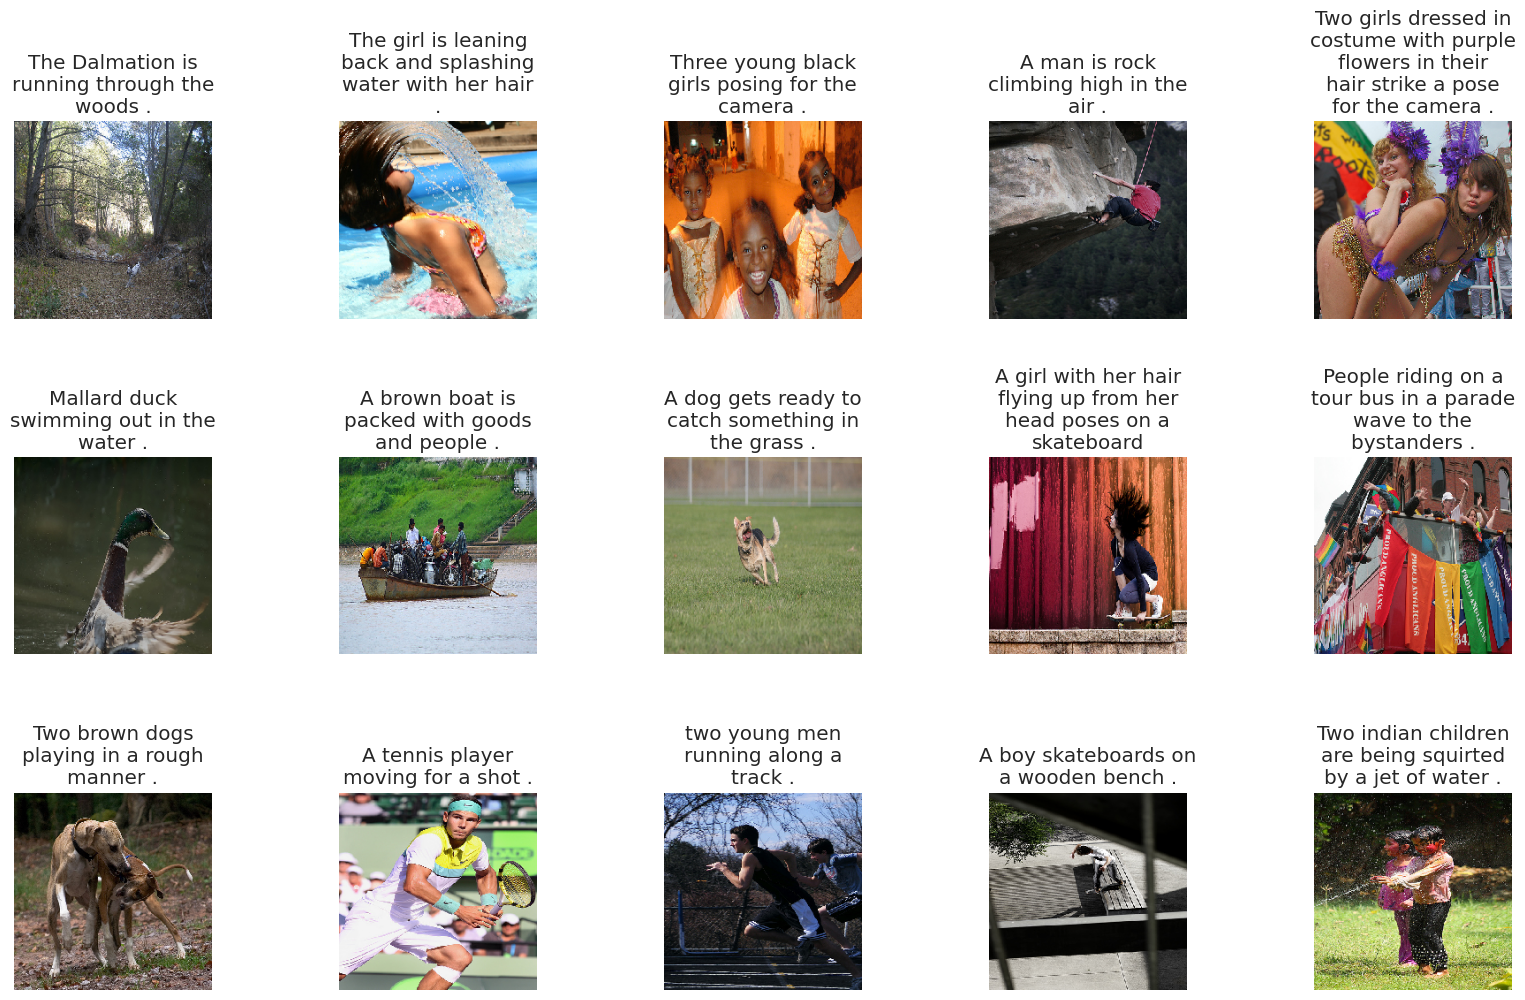

In [12]:
display_images(data.sample(15))

In [13]:
def text_preprocessing(data):
    data['caption'] = data['caption'].apply(lambda x: x.lower())
    data['caption'] = data['caption'].apply(lambda x: x.replace("[^A-Za-z]",""))
    data['caption'] = data['caption'].apply(lambda x: x.replace("\s+"," "))
    data['caption'] = data['caption'].apply(lambda x: " ".join([word for word in x.split() if len(word)>1]))
    data['caption'] = "startseq "+data['caption']+" endseq"
    return data

In [14]:
data = text_preprocessing(data)
captions = data['caption'].tolist()
captions[:10]

['startseq child in pink dress is climbing up set of stairs in an entry way endseq',
 'startseq girl going into wooden building endseq',
 'startseq little girl climbing into wooden playhouse endseq',
 'startseq little girl climbing the stairs to her playhouse endseq',
 'startseq little girl in pink dress going into wooden cabin endseq',
 'startseq black dog and spotted dog are fighting endseq',
 'startseq black dog and tri-colored dog playing with each other on the road endseq',
 'startseq black dog and white dog with brown spots are staring at each other in the street endseq',
 'startseq two dogs of different breeds looking at each other on the road endseq',
 'startseq two dogs on pavement moving toward each other endseq']

In [15]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(captions)
vocab_size = len(tokenizer.word_index) + 1
max_length = max(len(caption.split()) for caption in captions)

images = data['image'].unique().tolist()
nimages = len(images)

split_index = round(0.85*nimages)
train_images = images[:split_index]
val_images = images[split_index:]

train = data[data['image'].isin(train_images)]
test = data[data['image'].isin(val_images)]

train.reset_index(inplace=True,drop=True)
test.reset_index(inplace=True,drop=True)

tokenizer.texts_to_sequences([captions[1]])[0]

[1, 18, 315, 63, 195, 116, 2]

In [16]:
# تصحيح الامتداد التالف في ملف النصوص وتحديث الجدول
data['image'] = data['image'].str.replace('.jpg.1', '.jpg', regex=False)
data.to_csv("/content/archive/captions.txt", index=False)

In [17]:
# Import the DenseNet201 model from Keras applications
model = DenseNet201()  # Initialize the DenseNet201 model with default weights (typically ImageNet)

# Create a new model that takes the input of DenseNet201 and outputs the second-to-last layer's output
# This is done to extract image features instead of class predictions
fe = Model(inputs=model.input, outputs=model.layers[-2].output)

# Set the image size to 224x224 (this size is typically required for DenseNet201 input)
img_size = 224

# Initialize an empty dictionary to store the extracted features for each image
features = {}

# Loop through each unique image name in the 'data' DataFrame
for image in tqdm(data['image'].unique().tolist()):
    # Load the image from the specified path and resize it to the required size (224x224)
    img = load_img(os.path.join(image_path, image), target_size=(img_size, img_size))

    # Convert the image into a NumPy array (from PIL image to array)
    img = img_to_array(img)

    # Normalize pixel values to the range [0, 1] (originally, pixel values are in the range [0, 255])
    img = img / 255.

    # Add an additional dimension to the image to make it compatible with the model's expected input shape
    # The model expects input in the form (batch_size, height, width, channels), so we add an extra batch dimension
    img = np.expand_dims(img, axis=0)

    # Use the feature extraction model to generate a feature vector for the image
    # The verbose=0 parameter ensures that no progress information is printed
    feature = fe.predict(img, verbose=0)

    # Store the feature vector in the 'features' dictionary, using the image name as the key
    features[image] = feature


82524592/82524592 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


100%|██████████| 8091/8091 [16:52<00:00,  7.99it/s]


In [18]:

from tensorflow.keras.utils import Sequence, to_categorical
import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

class CustomDataGenerator(Sequence):
    """
    Custom Data Generator to yield batches of image features and corresponding caption sequences.

    Attributes:
    -----------
    df : DataFrame
        DataFrame containing image identifiers and their corresponding captions.
    X_col : str
        Name of the column in the DataFrame that contains image identifiers.
    y_col : str
        Name of the column in the DataFrame that contains captions.
    batch_size : int
        Number of samples per batch.
    directory : str
        Directory where the images are stored.
    tokenizer : Tokenizer
        Tokenizer object used to convert text into sequences of integers.
    vocab_size : int
        Size of the vocabulary for the output categorical sequences.
    max_length : int
        Maximum length for the input sequences (captions) to be padded.
    features : dict
        Dictionary containing image features extracted from a pre-trained model.
    shuffle : bool, optional
        Whether to shuffle the data at the end of each epoch (default is True).
    n : int
        Total number of samples in the DataFrame.
    """

    def __init__(self, df, X_col, y_col, batch_size, directory, tokenizer,
                 vocab_size, max_length, features, shuffle=True):
        """Initializes the generator with the given parameters."""
        self.df = df.copy()  # Make a copy of the DataFrame to avoid modifying the original one
        self.X_col = X_col  # Column name for image identifiers
        self.y_col = y_col  # Column name for captions
        self.directory = directory  # Directory where images are stored
        self.batch_size = batch_size  # Number of samples in each batch
        self.tokenizer = tokenizer  # Tokenizer to convert text to sequences
        self.vocab_size = vocab_size  # Size of the vocabulary for the captions
        self.max_length = max_length  # Maximum length of input sequences for padding
        self.features = features  # Pre-extracted features of the images
        self.shuffle = shuffle  # Whether to shuffle the data at the end of each epoch
        self.n = len(self.df)  # Total number of samples

    def on_epoch_end(self):
        """Shuffles the DataFrame at the end of each epoch if shuffle is True."""
        if self.shuffle:
            self.df = self.df.sample(frac=1).reset_index(drop=True)  # Shuffle the DataFrame

    def __len__(self):
        """Returns the number of batches per epoch."""
        return self.n // self.batch_size  # Floor division to get the number of complete batches

    def __getitem__(self, index):
        """Generates one batch of data."""
        batch = self.df.iloc[index * self.batch_size:(index + 1) * self.batch_size, :]  # Get batch samples
        X1, X2, y = self.__get_data(batch)  # Get data for the batch
        return (X1, X2), y  # Return inputs and output as a tuple

    def __get_data(self, batch):
        """Generates data for a given batch of samples."""
        X1, X2, y = list(), list(), list()  # Initialize empty lists to store features, input sequences, and outputs

        images = batch[self.X_col].tolist()  # Get list of image identifiers in the batch

        for image in images:
            feature = self.features[image][0]  # Extract pre-computed image feature from the features dictionary
            captions = batch.loc[batch[self.X_col] == image, self.y_col].tolist()  # Get captions for the image
            for caption in captions:
                seq = self.tokenizer.texts_to_sequences([caption])[0]  # Convert caption to sequence of integers

                for i in range(1, len(seq)):
                    # Split the caption into input and output sequences
                    in_seq, out_seq = seq[:i], seq[i]  # Input sequence and the next word as the output
                    in_seq = pad_sequences([in_seq], maxlen=self.max_length)[0]  # Pad input sequence to max_length
                    out_seq = to_categorical([out_seq], num_classes=self.vocab_size)[0]  # Convert output to one-hot encoding

                    X1.append(feature)  # Append image feature as input
                    X2.append(in_seq)  # Append the input sequence
                    y.append(out_seq)  # Append the output (next word in sequence)

        # Convert lists to NumPy arrays for better performance
        X1, X2, y = np.array(X1), np.array(X2), np.array(y)

        return X1, X2, y  # Return image features, input sequences, and output sequences


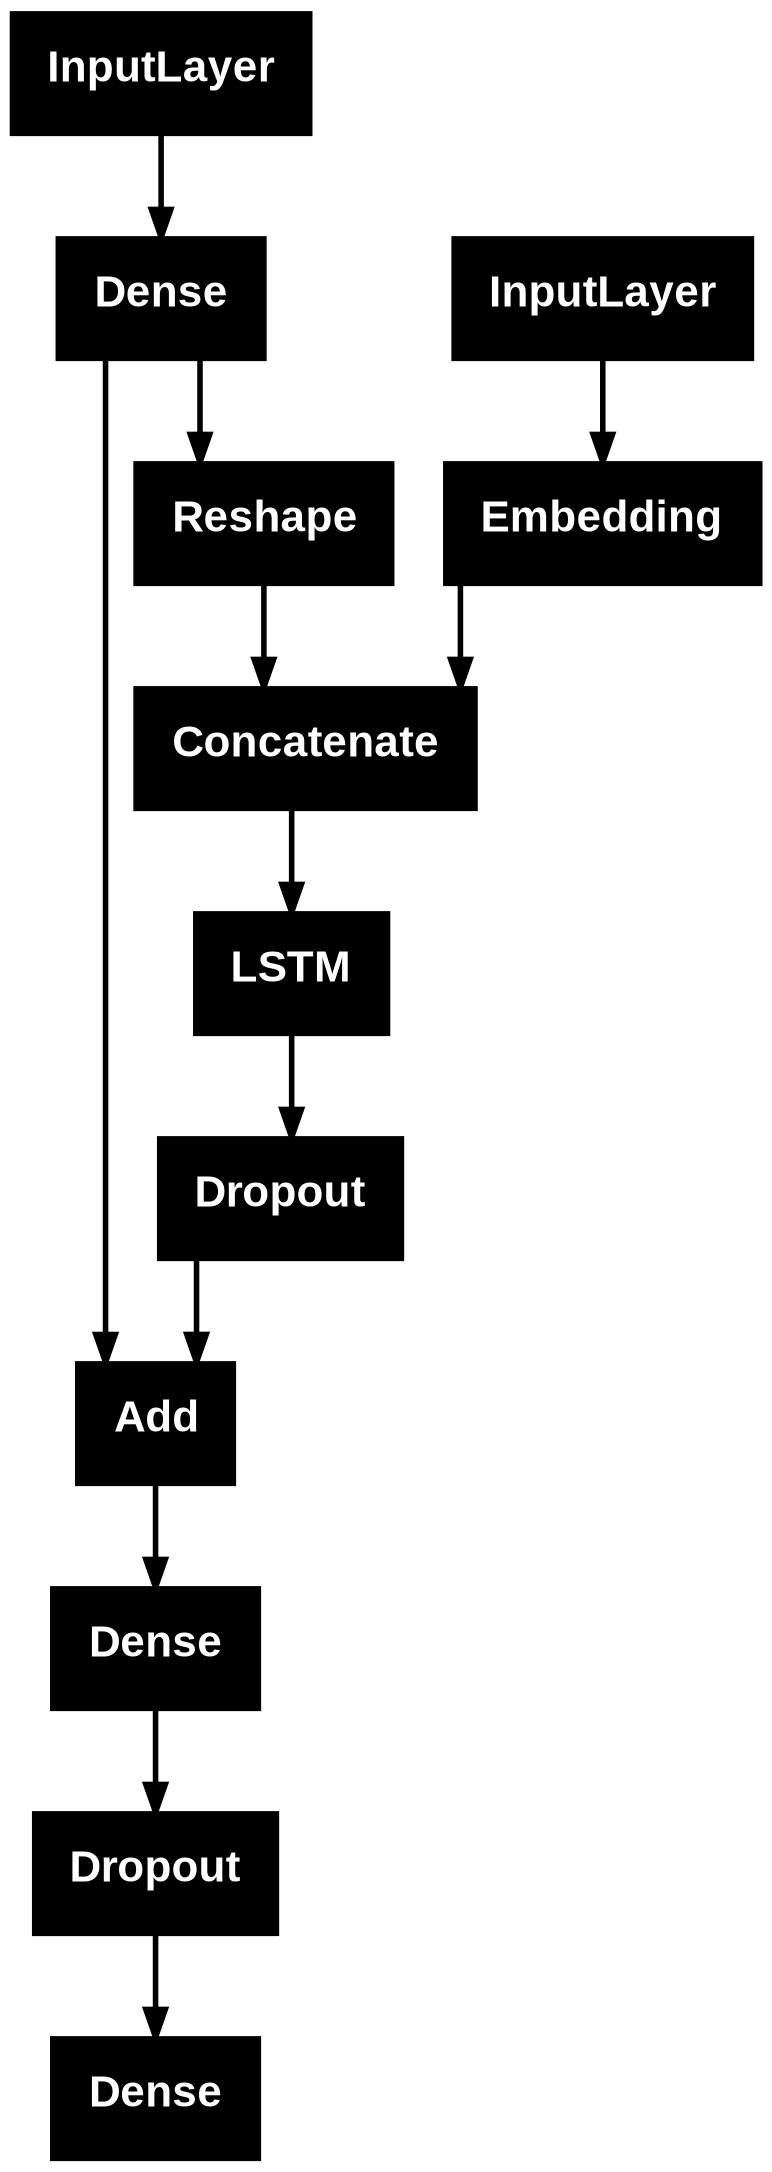

In [19]:
from tensorflow.keras.layers import Input, Dense, Reshape, Embedding, LSTM, Dropout, add, concatenate
from tensorflow.keras.models import Model

# Define two input layers
input1 = Input(shape=(1920,))  # Input for image features
input2 = Input(shape=(max_length,))  # Input for the caption sequence

# Image feature processing
img_features = Dense(256, activation='relu')(input1)  # Fully connected layer to reduce dimensionality
img_features_reshaped = Reshape((1, 256), input_shape=(256,))(img_features)  # Reshape to (1, 256) to concatenate with LSTM output

# Caption (text) processing
sentence_features = Embedding(vocab_size, 256, mask_zero=False)(input2)  # Embedding layer for input captions
merged = concatenate([img_features_reshaped, sentence_features], axis=1)  # Concatenate image features with caption sequence
sentence_features = LSTM(256)(merged)  # LSTM processes the combined features

# Combine LSTM output with image features
x = Dropout(0.5)(sentence_features)  # Dropout to prevent overfitting
x = add([x, img_features])  # Skip connection to add image features to LSTM output
x = Dense(128, activation='relu')(x)  # Fully connected layer
x = Dropout(0.5)(x)  # Dropout for regularization
output = Dense(vocab_size, activation='softmax')(x)  # Output layer with softmax activation to predict the next word

# Create and compile the model
caption_model = Model(inputs=[input1, input2], outputs=output)  # Define the model with two inputs and one output
caption_model.compile(loss='categorical_crossentropy', optimizer='adam')  # Compile the model with categorical crossentropy loss


from tensorflow.keras.utils import plot_model
plot_model(caption_model)

In [20]:
caption_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 1920)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    491,776 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 34)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 256)    │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 34, 256)   │  2,172,160 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 35, 256)   │          0 │ reshape[0][0],    │
│ (Concatenate)       │                   │            │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 256)       │    525,312 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 256)       │          0 │ dropout[0][0],    │
│                     │                   │            │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 8485)      │  1,094,565 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,316,709 (16.47 MB)

 Trainable params: 4,316,709 (16.47 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Create a training data generator
train_generator = CustomDataGenerator(
    df=train,  # DataFrame containing training data
    X_col='image',  # Column name with image identifiers
    y_col='caption',  # Column name with captions
    batch_size=64,  # Number of samples per batch
    directory=image_path,  # Path to the directory containing images
    tokenizer=tokenizer,  # Tokenizer to convert captions to sequences
    vocab_size=vocab_size,  # Total vocabulary size for one-hot encoding
    max_length=max_length,  # Maximum length for input sequences
    features=features  # Pre-computed image features
)

# Create a validation data generator
validation_generator = CustomDataGenerator(
    df=test,  # DataFrame containing validation data
    X_col='image',  # Column name with image identifiers
    y_col='caption',  # Column name with captions
    batch_size=64,  # Number of samples per batch
    directory=image_path,  # Path to the directory containing images
    tokenizer=tokenizer,  # Tokenizer to convert captions to sequences
    vocab_size=vocab_size,  # Total vocabulary size for one-hot encoding
    max_length=max_length,  # Maximum length for input sequences
    features=features  # Pre-computed image features
)


In [22]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

# Callback to save the model with the lowest validation loss
model_name = "model.keras"  # Change the file extension to '.keras'
checkpoint = ModelCheckpoint(
    model_name,  # Filepath where the model will be saved
    monitor="val_loss",  # Monitor the validation loss during training
    mode="min",  # Save the model when the validation loss is minimized
    save_best_only=True,  # Save only the model with the best validation loss
    verbose=1  # Print a message when the model is saved
)

# Callback to stop training early if the validation loss does not improve
earlystopping = EarlyStopping(
    monitor='val_loss',  # Monitor the validation loss
    min_delta=0,  # Minimum change in the monitored value to be considered an improvement
    patience=5,  # Number of epochs with no improvement after which training will be stopped
    verbose=1,  # Print a message when early stopping is triggered
    restore_best_weights=True  # Restore model weights from the epoch with the best validation loss
)

# Callback to reduce the learning rate if validation loss does not improve
learning_rate_reduction = ReduceLROnPlateau(
    monitor='val_loss',  # Monitor the validation loss
    patience=3,  # Number of epochs with no improvement after which the learning rate will be reduced
    verbose=1,  # Print a message when the learning rate is reduced
    factor=0.2,  # Factor by which the learning rate will be reduced (new_lr = lr * factor)
    min_lr=1e-8  # Lower bound on the learning rate to avoid reducing it too much
)


In [23]:
# Train the image captioning model
history = caption_model.fit(
    train_generator,  # Training data generator
    epochs=5,  # Maximum number of epochs to train the model
    validation_data=validation_generator,  # Validation data generator
    callbacks=[checkpoint, earlystopping, learning_rate_reduction]  # List of callbacks to monitor and control training
)


Epoch 1/5
537/537 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - loss: 5.6917
Epoch 1: val_loss improved from None to 4.26662, saving model to model.keras

Epoch 1: finished saving model to model.keras
537/537 ━━━━━━━━━━━━━━━━━━━━ 90s 157ms/step - loss: 5.0818 - val_loss: 4.2666 - learning_rate: 0.0010
Epoch 2/5
537/537 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - loss: 4.3061
Epoch 2: val_loss improved from 4.26662 to 3.95419, saving model to model.keras

Epoch 2: finished saving model to model.keras
537/537 ━━━━━━━━━━━━━━━━━━━━ 84s 157ms/step - loss: 4.2504 - val_loss: 3.9542 - learning_rate: 0.0010
Epoch 3/5
537/537 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - loss: 4.0085
Epoch 3: val_loss improved from 3.95419 to 3.79553, saving model to model.keras

Epoch 3: finished saving model to model.keras
537/537 ━━━━━━━━━━━━━━━━━━━━ 83s 155ms/step - loss: 3.9822 - val_loss: 3.7955 - learning_rate: 0.0010
Epoch 4/5
537/537 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - loss: 3.8342
Epoch 4: val_loss improved from 3.79553 to 3

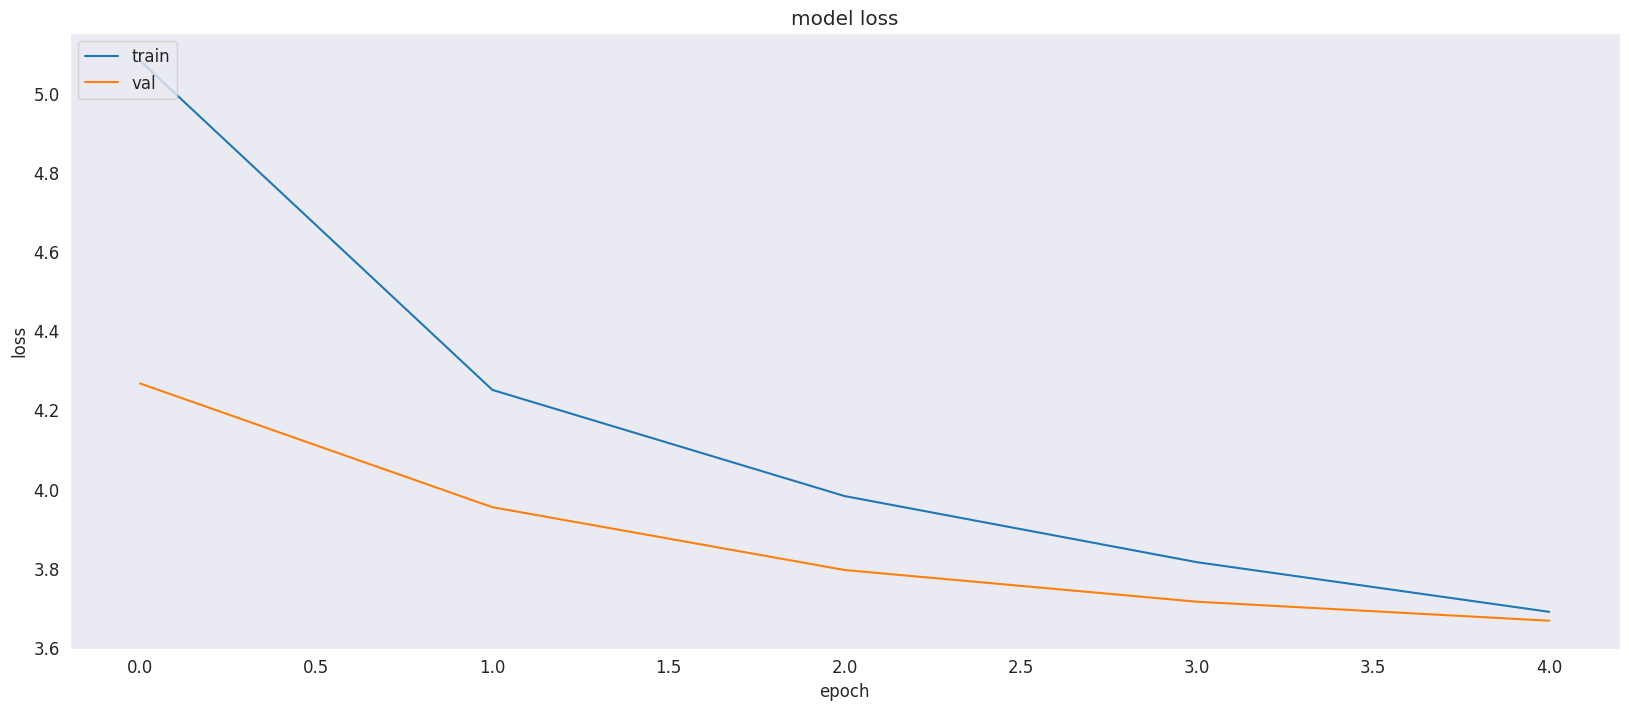

In [24]:
plt.figure(figsize=(20,8))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

Building the dictionary...
Loading your saved model (model.keras)...
Dictionary built successfully! Model expected length: 34
Loading DenseNet201...
Testing 5 images...


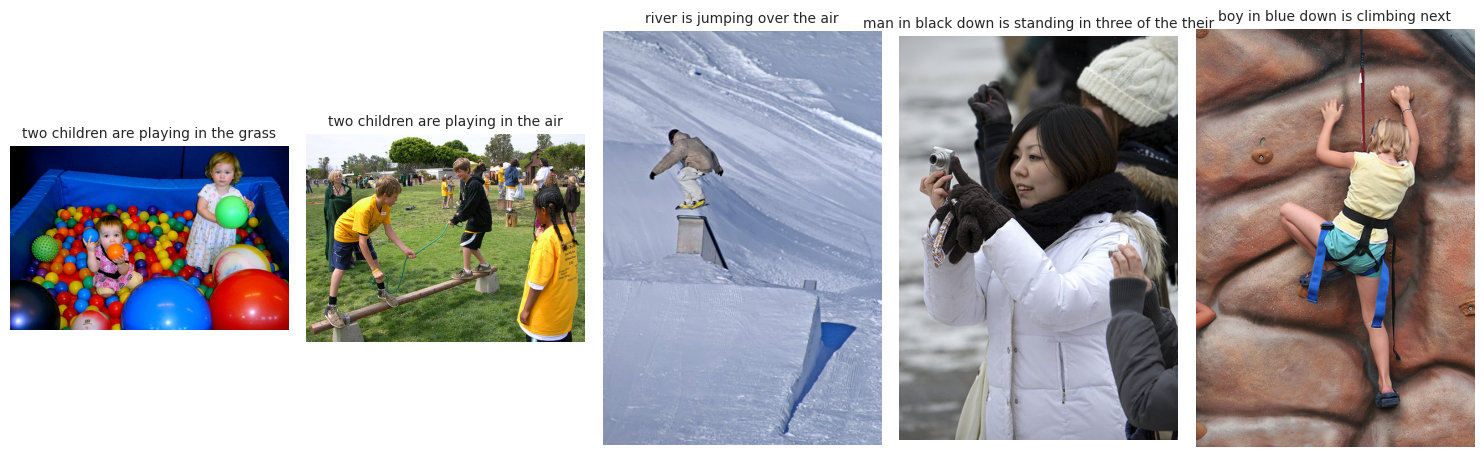

In [27]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.applications.densenet import DenseNet201

# ==========================================
# 1. Setting up paths (Cloud paths for Google Colab)
# ==========================================
TEST_IMAGES_FOLDER = "/content/archive/Images"
CAPTIONS_FILE = "/content/archive/captions.txt"

# ==========================================
# 2. Building the Dictionary (Tokenizer) in 3 seconds
# ==========================================
print("Building the dictionary...")
data = pd.read_csv(CAPTIONS_FILE)

data['caption'] = data['caption'].str.lower()
data['caption'] = data['caption'].str.replace(r'[^a-z\s]', '', regex=True)
data['caption'] = data['caption'].str.replace(r'\s+', ' ', regex=True)
data['caption'] = data['caption'].apply(lambda x: " ".join([word for word in x.split() if len(word) > 1]))
data['caption'] = "startseq " + data['caption'] + " endseq"

captions = data['caption'].tolist()
tokenizer = Tokenizer()
tokenizer.fit_on_texts(captions)

# ==========================================
# 3. Loading your saved model and feature extraction model
# ==========================================
print("Loading your saved model (model.keras)...")
caption_model = load_model("model.keras")

# استخراج الطول الدقيق الذي تدرب عليه النموذج (34) تلقائياً
max_length = caption_model.input_shape[1][1]
print(f"Dictionary built successfully! Model expected length: {max_length}")

print("Loading DenseNet201...")
base_model = DenseNet201(weights='imagenet')
feature_extractor = Model(inputs=base_model.input, outputs=base_model.layers[-2].output)

# ==========================================
# 4. Text Generation Function for New Images
# ==========================================
def generate_caption(model, tokenizer, max_length, feature):
    in_text = 'startseq'
    for i in range(max_length):
        sequence = tokenizer.texts_to_sequences([in_text])[0]
        sequence = pad_sequences([sequence], maxlen=max_length)

        yhat = model.predict([feature, sequence], verbose=0)
        yhat = np.argmax(yhat)

        word = tokenizer.index_word.get(yhat)
        if word is None:
            break
        in_text += ' ' + word
        if word == 'endseq':
            break

    return in_text.replace('startseq', '').replace('endseq', '').strip()

# ==========================================
# 5. Testing 5 Random Images
# ==========================================
print("Testing 5 images...")
valid_exts = ('.jpg', '.jpeg', '.png')
all_files = [f for f in os.listdir(TEST_IMAGES_FOLDER) if f.lower().endswith(valid_exts)]
random_images = random.sample(all_files, min(5, len(all_files)))

plt.figure(figsize=(15, 5))

for i, img_name in enumerate(random_images):
    img_path = os.path.join(TEST_IMAGES_FOLDER, img_name)

    img = load_img(img_path, target_size=(224, 224))
    img_array = img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    feature = feature_extractor.predict(img_array, verbose=0)
    caption = generate_caption(caption_model, tokenizer, max_length, feature)

    ax = plt.subplot(1, 5, i + 1)
    disp_img = load_img(img_path)
    plt.imshow(disp_img)
    plt.title(caption, wrap=True, fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()


✍️ اكتبي كلمة أو جملة بالإنجليزية (أو اكتبي exit للخروج): black dog running in water

🔎 نتائج البحث عن: 'black dog running in water' (أقرب 5 صور):


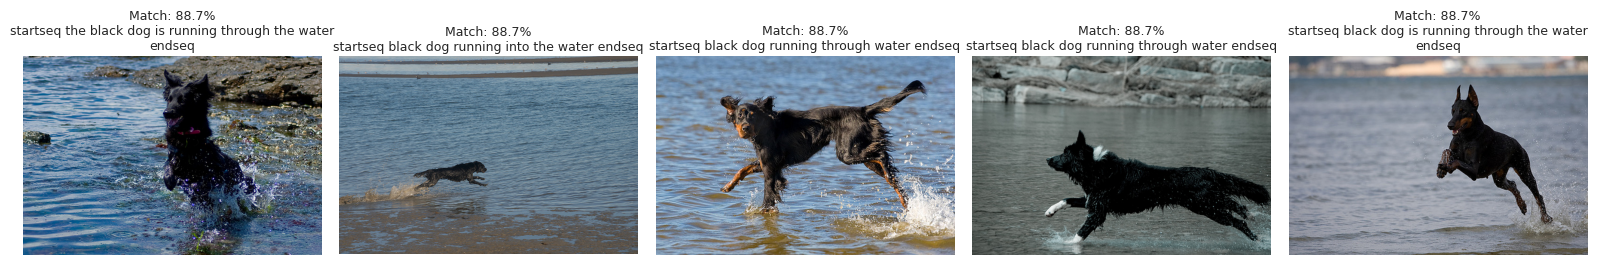

In [ ]:
### التكليفف

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

IMAGES_FOLDER = "/content/archive/Images"
CAPTIONS_FILE = "/content/archive/captions.txt"

data = pd.read_csv(CAPTIONS_FILE)
data['clean_caption'] = (
    data['caption'].astype(str).str.lower()
    .str.replace(r'[^a-z\s]', '', regex=True)
    .str.replace(r'\s+', ' ', regex=True).str.strip()
)
vectorizer = TfidfVectorizer(ngram_range=(1, 2), stop_words='english')
tfidf_matrix = vectorizer.fit_transform(data['clean_caption'])


def search_images_by_caption(query, top_k=5):
    clean_query = query.lower().strip()
    query_vec = vectorizer.transform([clean_query])


    similarities = cosine_similarity(query_vec, tfidf_matrix).flatten()

    temp_df = data.copy()
    temp_df['score'] = similarities

    best_matches = (
        temp_df[temp_df['score'] > 0]
        .sort_values(by='score', ascending=False)
        .drop_duplicates(subset=['image'])
        .head(top_k)
    )

    if best_matches.empty:
        print(f"لم يتم العثور على صور مطابقة للنص: '{query}'")
        return

    print(f"\n🔎 نتائج البحث عن: '{query}' (أقرب {len(best_matches)} صور):")
    plt.figure(figsize=(16, 4))

    for idx, (_, row) in enumerate(best_matches.iterrows()):
        img_path = os.path.join(IMAGES_FOLDER, row['image'])
        if os.path.exists(img_path):
            ax = plt.subplot(1, top_k, idx + 1)
            plt.imshow(Image.open(img_path))
            plt.title(f"Match: {row['score']*100:.1f}%\n{row['caption']}", wrap=True, fontsize=9)
            plt.axis("off")

    plt.tight_layout()
    plt.show()

while True:
    user_input = input("\n✍️ اكتبي كلمة أو جملة بالإنجليزية (أو اكتبي exit للخروج): ")
    if user_input.strip().lower() in ['exit', 'quit', 'خروج']:
        print("تم إنهاء البحث.")
        break
    if user_input.strip():

        search_images_by_caption(user_input, top_k=5)